# OLAP Куб для анализа преступлений

In [46]:
import pandas as pd
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Настройка отображения графиков
plt.style.use('default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10


In [47]:
from pathlib import Path

# Локальный каталог с датасетами: datasets are in la_crimes/la_crimes
DATA_DIR = Path(r'C:\Users\alexm\Downloads\olap_8\la_crimes\la_crimes')
DATA_DIR

WindowsPath('C:/Users/alexm/Downloads/olap_8/la_crimes/la_crimes')

## Загрузка данных


In [48]:
df = pd.read_csv(DATA_DIR / 'CrimeDataNormalized.csv', encoding='utf-8-sig')

print(f"Загружено строк: {len(df):,}")
print(f"Количество столбцов: {len(df.columns)}")

Загружено строк: 1,048,575
Количество столбцов: 17


In [49]:
df.head()

,Digital Record Number,Date Reported,Date of Occurrence,Time of Occurrence,Area Name,SubArea Number,CrimeCodeDescription,Victim Age,Victim Gender,Victim OriginalCountry,Premise Code,Weapon Description,Status Desc,Latitude,Longitude,Location,Severity
0,190326475.0,3/1/2020,3/1/2020,2130.0,7.0,784.0,510.0,0.0,M,O,101.0,0.0,Adult Arrest,34.0375,-118.3506,1900 S Longwoodav,8
1,200106753.0,2/9/2020,2/8/2020,1800.0,1.0,182.0,330.0,47.0,M,O,128.0,0.0,Invest Cont,34.0444,-118.2628,1000 S Flower St,4
2,200320258.0,11/11/2020,11/4/2020,1700.0,3.0,356.0,480.0,19.0,X,NaN,502.0,0.0,Invest Cont,34.0210,-118.3002,1400 W 37Th St,4
3,200907217.0,5/10/2023,3/10/2020,2037.0,9.0,964.0,343.0,19.0,M,O,405.0,0.0,Invest Cont,34.1576,-118.4387,14000 Riverside Dr,1
4,200412582.0,9/9/2020,9/9/2020,630.0,4.0,413.0,510.0,0.0,X,NaN,101.0,0.0,Invest Cont,34.0820,-118.2130,200 E Avenue 28,3


## Загрузка справочных таблиц и соединение данных


In [50]:
crime_desc = pd.read_csv(DATA_DIR / 'CrimeCodeDescription.csv', encoding='utf-8-sig')
crime_desc.columns = crime_desc.columns.str.strip()
crime_desc = crime_desc.rename(columns={'Crime Code': 'CrimeCode', 'CrimeCodeDescription': 'CrimeDescription'})
crime_desc['CrimeCode'] = pd.to_numeric(crime_desc['CrimeCode'], errors='coerce').map(lambda x: str(int(x)) if pd.notna(x) else np.nan)

area_desc = pd.read_csv(DATA_DIR / 'AreaCodeDescription.csv', encoding='utf-8-sig')
area_desc.columns = area_desc.columns.str.strip()
area_desc = area_desc.rename(columns={'AreaCode': 'AreaCode', 'Area Name': 'AreaName'})
area_desc['AreaCode'] = pd.to_numeric(area_desc['AreaCode'], errors='coerce').map(lambda x: str(int(x)) if pd.notna(x) else np.nan)

weapon_desc = pd.read_csv(DATA_DIR / 'WeaponCodeDescription.csv', encoding='utf-8-sig')
weapon_desc.columns = weapon_desc.columns.str.strip()
weapon_desc = weapon_desc.rename(columns={'Weapon Used Code': 'WeaponCode', 'Weapon Description': 'WeaponDescription'})
weapon_desc['WeaponCode'] = pd.to_numeric(weapon_desc['WeaponCode'], errors='coerce').map(lambda x: str(int(x)) if pd.notna(x) else np.nan)

premise_desc = pd.read_csv(DATA_DIR / 'PremiseCodeDescription.csv', encoding='utf-8-sig')
premise_desc.columns = premise_desc.columns.str.strip()
premise_desc = premise_desc.rename(columns={'Premise Code': 'PremiseCode', 'PremiseDescription': 'PremiseDescription'})
premise_desc['PremiseCode'] = pd.to_numeric(premise_desc['PremiseCode'], errors='coerce').map(lambda x: str(int(x)) if pd.notna(x) else np.nan)


In [51]:
# Нормализованный датасет хранит числовые коды справочников
df['AreaCode'] = pd.to_numeric(df['Area Name'], errors='coerce').map(lambda x: str(int(x)) if pd.notna(x) else np.nan)
df['CrimeCode'] = pd.to_numeric(df['CrimeCodeDescription'], errors='coerce').map(lambda x: str(int(x)) if pd.notna(x) else np.nan)
df['WeaponCode'] = pd.to_numeric(df['Weapon Description'], errors='coerce').map(lambda x: str(int(x)) if pd.notna(x) else np.nan)
df['PremiseCode'] = pd.to_numeric(df['Premise Code'], errors='coerce').map(lambda x: str(int(x)) if pd.notna(x) else np.nan)

df = df.merge(crime_desc[['CrimeCode', 'CrimeDescription']],
              left_on='CrimeCode',
              right_on='CrimeCode',
              how='left')

df = df.merge(area_desc[['AreaCode', 'AreaName']],
              left_on='AreaCode',
              right_on='AreaCode',
              how='left')

df = df.merge(weapon_desc[['WeaponCode', 'WeaponDescription']],
              left_on='WeaponCode',
              right_on='WeaponCode',
              how='left')

df = df.merge(premise_desc[['PremiseCode', 'PremiseDescription']],
              left_on='PremiseCode',
              right_on='PremiseCode',
              how='left')

df['CrimeCodeDescription'] = df['CrimeDescription'].fillna(df['CrimeCodeDescription'])
df['Area Name'] = df['AreaName'].fillna(df['Area Name'])
df['Weapon Description'] = df['WeaponDescription'].fillna(df['Weapon Description'])
df['Premise Description'] = df['PremiseDescription'].fillna(df['Premise Code'])

In [52]:
df.head()


,Digital Record Number,Date Reported,Date of Occurrence,Time of Occurrence,Area Name,SubArea Number,CrimeCodeDescription,Victim Age,Victim Gender,Victim OriginalCountry,...,Severity,AreaCode,CrimeCode,WeaponCode,PremiseCode,CrimeDescription,AreaName,WeaponDescription,PremiseDescription,Premise Description
0,190326475.0,3/1/2020,3/1/2020,2130.0,Wilshire,784.0,Vehicle - Stolen,0.0,M,O,...,8,7,510,0,101,Vehicle - Stolen,Wilshire,Unknown,Street,Street
1,200106753.0,2/9/2020,2/8/2020,1800.0,Central,182.0,Burglary From Vehicle,47.0,M,O,...,4,1,330,0,128,Burglary From Vehicle,Central,Unknown,Bus Stop/Layover (Also Query 124),Bus Stop/Layover (Also Query 124)
2,200320258.0,11/11/2020,11/4/2020,1700.0,Southwest,356.0,Bike - Stolen,19.0,X,NaN,...,4,3,480,0,502,Bike - Stolen,Southwest,Unknown,"Multi-Unit Dwelling (Apartment, Duplex, Etc)","Multi-Unit Dwelling (Apartment, Duplex, Etc)"
3,200907217.0,5/10/2023,3/10/2020,2037.0,Van Nuys,964.0,Shoplifting-Grand Theft ($950.01 & Over),19.0,M,O,...,1,9,343,0,405,Shoplifting-Grand Theft ($950.01 & Over),Van Nuys,Unknown,Clothing Store,Clothing Store
4,200412582.0,9/9/2020,9/9/2020,630.0,Hollenbeck,413.0,Vehicle - Stolen,0.0,X,NaN,...,3,4,510,0,101,Vehicle - Stolen,Hollenbeck,Unknown,Street,Street


In [53]:
df['Date of Occurrence'] = pd.to_datetime(df['Date of Occurrence'], errors='coerce')
df['Date Reported'] = pd.to_datetime(df['Date Reported'], errors='coerce')

df['Year'] = df['Date of Occurrence'].dt.year
df['Month'] = df['Date of Occurrence'].dt.month
df['Quarter'] = df['Date of Occurrence'].dt.quarter
df['YearMonth'] = df['Date of Occurrence'].dt.to_period('M')

df['Victim Gender'] = df['Victim Gender'].astype(str)
df['Severity'] = pd.to_numeric(df['Severity'], errors='coerce')


## Создание OLAP куба

OLAP куб будет иметь следующие измерения:
- **Area Name** - область
- **CrimeCodeDescription** - тип преступления
- **Weapon Description** - тип оружия
- **Year, Quarter, Month** - временные измерения
- **Victim Gender** - пол жертвы
- **Severity** - уровень серьезности

Метрики:
- Количество преступлений (Count)
- Уровень серьезности (Severity)
- Dозраст жертвы (Victim Age)


In [54]:
df['Crime Count'] = 1

df_clean = df.dropna(subset=['Area Name', 'CrimeCodeDescription', 'Year'])


#ЧАСТЬ 1: Простые OLAP срезы

(для решения использовать pivot pandas)
Выполните следующие срезы по имеющимся метрикам

### Срез 1: Преступления по областям и годам

Добавьте визуализацию


In [55]:
cube_area_year = pd.pivot_table(
    df_clean,
    values=['Crime Count', 'Severity', 'Victim Age'],
    index='Area Name',
    columns='Year',
    aggfunc={
        'Crime Count': 'count',
        'Severity': 'mean',
        'Victim Age': 'mean'
    },
    fill_value=0
)

cube_area_year


Crime Count                              Severity            \
Year             2020.0 2021.0 2022.0 2023.0 2024.0    2020.0    2021.0   
Area Name                                                                 
77th Street       13350  13100  14573  13952   6769  5.518801  5.493435   
Central           11604  13171  17715  16967  10203  5.482161  5.453193   
Devonshire         7984   8507   9597   9776   5876  5.481588  5.510051   
Foothill           7107   7048   7867   7159   3946  5.484171  5.489075   
Harbor             8875   8875   9200   9135   5293  5.503099  5.474479   
Hollenbeck         7807   8028   8522   8409   4308  5.530550  5.504484   
Hollywood         10174  12108  12546  11454   6149  5.467270  5.527833   
Mission            8483   8238   9279   8981   5358  5.550277  5.511289   
N Hollywood       10169  10932  11199  11558   7239  5.488937  5.461855   
Newton             9995   9926  11933  11933   5385  5.560480  5.489925   
Northeast          8452   9351  10184   9715   5241  5.536678  5.503262   
Olympic            9640  10834  12066  11753   5765  5.494191  5.507384   
Pacific           11575  12934  13048  13792   8082  5.510497  5.497449   
Rampart            9025   9464  11204  11530   5600  5.520665  5.502959   
Southeast         10849  10434  11747  11294   5601  5.501244  5.523002   
Southwest         11180  11419  13416  13112   8293  5.466190  5.527542   
Topanga            8113   8604   9462   9648   5536  5.536916  5.439679   
Van Nuys           8764   8700   9715   9941   5752  5.482656  5.569885   
West LA            9311   9900  10515  10587   5408  5.543443  5.493737   
West Valley        8095   8543  10288   9937   5270  5.439654  5.447852   
Wilshire           9292   9752  11176  11718   6292  5.542725  5.490771   

                                          Victim Age                        \
Year           2022.0    2023.0    2024.0     2020.0     2021.0     2022.0   
Area Name                                                                    
77th Street  5.473959  5.506021  5.521643  29.603745  29.671069  29.762232   
Central      5.467683  5.515000  5.478977  30.345226  30.407942  30.344849   
Devonshire   5.493488  5.492533  5.482301  30.401303  30.327377  30.931020   
Foothill     5.462057  5.458723  5.513685  30.762910  31.638905  30.879115   
Harbor       5.471739  5.492063  5.524277  28.287211  28.562930  28.135435   
Hollenbeck   5.502816  5.562017  5.519731  26.334187  27.129796  26.953884   
Hollywood    5.494978  5.540946  5.494227  28.739827  28.431203  29.285669   
Mission      5.524410  5.445941  5.492348  29.946363  30.689124  30.585839   
N Hollywood  5.481204  5.502509  5.525349  29.726325  29.612605  29.732030   
Newton       5.508422  5.497695  5.488579  25.829815  26.184264  26.419928   
Northeast    5.491359  5.513330  5.499523  28.690606  29.115282  29.291634   
Olympic      5.506547  5.517825  5.494016  27.972303  28.603563  28.802254   
Pacific      5.498467  5.452509  5.487256  29.277754  29.774702  30.190987   
Rampart      5.440914  5.534172  5.510536  28.362992  27.833263  28.350500   
Southeast    5.459181  5.528157  5.519550  28.838234  28.209603  29.052098   
Southwest    5.493292  5.485357  5.519595  31.374866  30.524564  30.749702   
Topanga      5.530755  5.511920  5.478324  36.172439  36.230009  35.146058   
Van Nuys     5.509727  5.467458  5.505216  33.102351  32.881034  33.600412   
West LA      5.515264  5.525078  5.471524  33.811406  34.409091  31.712506   
West Valley  5.512539  5.478817  5.568880  31.719951  31.434859  31.944110   
Wilshire     5.500000  5.508534  5.450890  33.422729  31.656891  29.586077   

                                   
Year            2023.0     2024.0  
Area Name                          
77th Street  28.315725  24.984193  
Central      28.958272  19.422523  
Devonshire   30.488441  24.599217  
Foothill     29.494063  24.231120  
Harbor       27.002299  21.842244  
Hollenbeck   25.845404  18.400882  
Hollywood    2

<Figure size 1400x800 with 0 Axes>

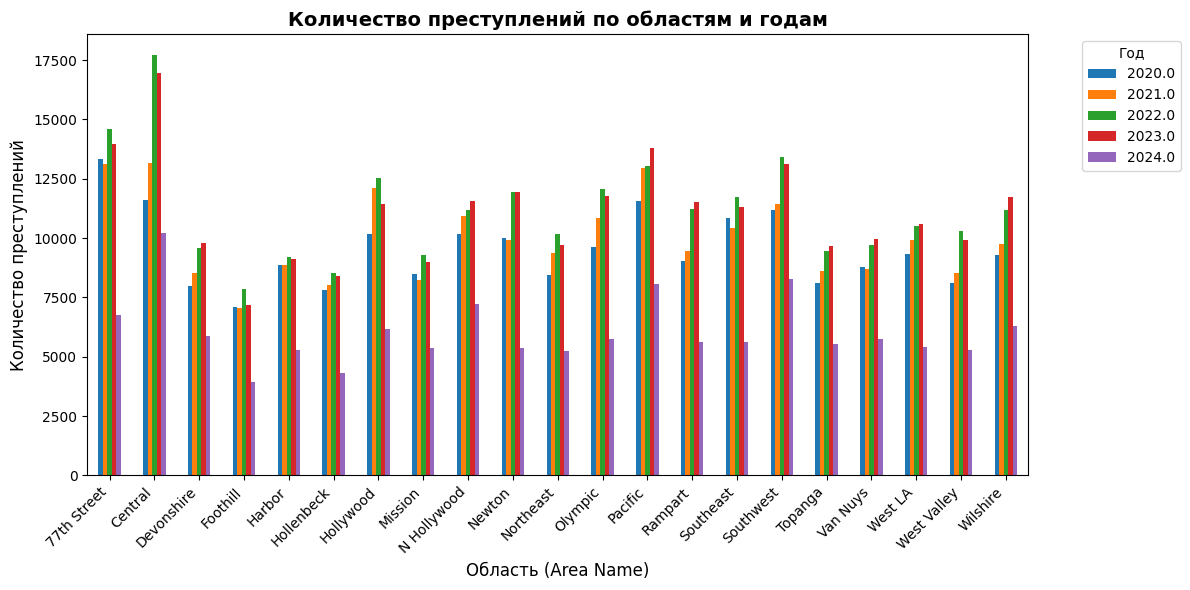

In [56]:
crime_count_by_area_year = cube_area_year['Crime Count']

plt.figure(figsize=(14, 8))
crime_count_by_area_year.plot(kind='bar', stacked=False)
plt.title('Количество преступлений по областям и годам', fontsize=14, fontweight='bold')
plt.xlabel('Область (Area Name)', fontsize=12)
plt.ylabel('Количество преступлений', fontsize=12)
plt.legend(title='Год', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


### Срез 2: Преступления по типам и оружию

Выведите топ-10 преступлений и используемое в них оружие. Проанализируйте метрики на пересечениях


In [57]:
cube_crime_weapon = pd.pivot_table(
    df_clean,
    values=['Crime Count', 'Severity'],
    index='CrimeCodeDescription',
    columns='Weapon Description',
    aggfunc={
        'Crime Count': 'count',
        'Severity': 'mean'
    },
    fill_value=0
)

top_crimes = pd.pivot_table(df_clean, values='Crime Count', index='CrimeCodeDescription', aggfunc='count', fill_value=0)['Crime Count'].head(10).index
cube_crime_weapon.loc[top_crimes]


Crime Count  \
Weapon Description                                 Air Pistol/Revolver/Rifle/Bb Gun   
CrimeCodeDescription                                                                  
Arson                                                                             0   
Assault With Deadly Weapon On Police Officer                                     12   
Assault With Deadly Weapon, Aggravated Assault                                 1202   
Attempted Robbery                                                                39   
Battery - Simple Assault                                                         12   
Battery On A Firefighter                                                          0   
Battery Police (Simple)                                                           0   
Battery With Sexual Contact                                                       0   
Beastiality, Crime Against Nature Sexual Asslt ...                                0   
Bigamy                                                                            0   

                                                                    \
Weapon Description                                 Antique Firearm   
CrimeCodeDescription                                                 
Arson                                                            0   
Assault With Deadly Weapon On Police Officer                     0   
Assault With Deadly Weapon, Aggravated Assault                   1   
Attempted Robbery                                                0   
Battery - Simple Assault                                         0   
Battery On A Firefighter                                         0   
Battery Police (Simple)                                          0   
Battery With Sexual Contact                                      0   
Beastiality, Crime Against Nature Sexual Asslt ...               0   
Bigamy                                                           0   

                                                                                \
Weapon Description                                 Assault Weapon/Uzi/Ak47/Etc   
CrimeCodeDescription                                                             
Arson                                                                        0   
Assault With Deadly Weapon On Police Officer                                 0   
Assault With Deadly Weapon, Aggravated Assault                              24   
Attempted Robbery                                                            4   
Battery - Simple Assault                                                     0   
Battery On A Firefighter                                                     0   
Battery Police (Simple)                                                      0   
Battery With Sexual Contact                                                  0   
Beastiality, Crime Against Nature Sexual Asslt ...                           0   
Bigamy                                                                       0   

                                                                                     \
Weapon Description                                 Automatic Weapon/Sub-Machine Gun   
CrimeCodeDescription                                                                  
Arson                                                                             0   
Assault With Deadly Weapon On Police Officer                                      0   
Assault With Deadly Weapon, Aggravated Assault                                    9   
Attempted Robbery                                                                 0   
Battery - Simple Assault                                                          0   
Battery On A Firefighter                                                          0   
Battery Police (Simple)                                                           0   
Battery With Sexual Contact                                                       0   
Beast

### Срез 3: Преступления по областям, типам и временным кварталам

Выведите топ-5 комбинаций

In [58]:
cube_area_crime_quarter = pd.pivot_table(
    df_clean,
    values=['Crime Count', 'Severity'],
    index=['Area Name', 'CrimeCodeDescription'],
    columns='Quarter',
    aggfunc={
        'Crime Count': 'count',
        'Severity': 'mean'
    },
    fill_value=0
)

top_combinations = df_clean.groupby(['Area Name', 'CrimeCodeDescription']).size().nlargest(5).index
cube_area_crime_quarter.loc[top_combinations]


Crime Count                    Severity  \
Quarter                                      1.0   2.0   3.0   4.0       1.0   
Area Name   CrimeCodeDescription                                               
Central     Burglary From Vehicle           2398  2108  2454  2728  5.430776   
77th Street Vehicle - Stolen                1994  2299  2402  2071  5.611836   
Newton      Vehicle - Stolen                1876  2281  2191  1933  5.605544   
Southeast   Vehicle - Stolen                1683  1748  1987  1824  5.638146   
Central     Battery - Simple Assault        1833  1621  1763  1589  5.429896   

                                                                    
Quarter                                    2.0       3.0       4.0  
Area Name   CrimeCodeDescription                                    
Central     Burglary From Vehicle     5.402751  5.454768  5.553152  
77th Street Vehicle - Stolen          5.475424  5.509992  5.507001  
Newton      Vehicle - Stolen          5.565980  5.494751  5.575789  
Southeast   Vehicle - Stolen          5.558352  5.598893  5.539474  
Central     Battery - Simple Assault  5.394201  5.602382  5.475142

### Срез 4: Преступления по полу жертвы и уровню серьезности

Объедините серьезность в группы


In [59]:
df_clean['Severity Category'] = pd.cut(
    df_clean['Severity'],
    bins=[0, 3, 6, 8, 10],
    labels=['Низкая (1-3)', 'Средняя (4-6)', 'Высокая (7-8)', 'Критическая (9-10)']
)

cube_gender_severity = pd.pivot_table(
    df_clean,
    values=['Crime Count', 'Victim Age'],
    index='Victim Gender',
    columns='Severity Category',
    aggfunc={
        'Crime Count': 'count',
        'Victim Age': 'mean'
    },
    fill_value=0
)

cube_gender_severity


Crime Count                                                 \
Severity Category Низкая (1-3) Средняя (4-6) Высокая (7-8) Критическая (9-10)   
Victim Gender                                                                   
F                       107505        107611         71677              71689   
M                       121544        120888         80471              80848   
X                        72820         72464         48473              48691   

                    Victim Age                                                 
Severity Category Низкая (1-3) Средняя (4-6) Высокая (7-8) Критическая (9-10)  
Victim Gender                                                                  
F                    38.222213     38.288484     38.297125          38.398081  
M                    37.259898     37.379169     37.328864          37.267626  
X                     1.087133      1.082289      1.090483           1.058861

### Срез 5: Временной анализ по месяцам

Визуализируйте динамику количества

In [60]:
cube_time_area = pd.pivot_table(
    df_clean,
    values=['Crime Count', 'Severity'],
    index='YearMonth',
    columns='Area Name',
    aggfunc={
        'Crime Count': 'sum',
        'Severity': 'mean'
    },
    fill_value=0
)

cube_time_area.tail(12)


Crime Count                                                          \
Area Name 77th Street Central Devonshire Foothill Harbor Hollenbeck Hollywood   
YearMonth                                                                       
2024-01          1073    1471        819      533    785        677       917   
2024-02           933    1262        778      543    684        683       893   
2024-03          1084     847        814      540    766        325       935   
2024-04          1009     611        704      561    708        294       472   
2024-05           515     661        549      367    357        269       397   
2024-06           345     867        367      249    268        288       379   
2024-07           365    1041        353      218    290        309       390   
2024-08           319     988        372      227    289        314       411   
2024-09           364     718        330      203    313        280       396   
2024-10           292     701        307      207    315        344       429   
2024-11           307     583        287      185    278        288       316   
2024-12           163     453        196      113    240        237       214   

                                      ...  Severity                      \
Area Name Mission N Hollywood Newton  ...   Olympic   Pacific   Rampart   
YearMonth                             ...                                 
2024-01       738        1018    897  ...  5.454171  5.536232  5.463928   
2024-02       633         946    846  ...  5.404279  5.336024  5.465261   
2024-03       665        1011    508  ...  5.504376  5.438492  5.522330   
2024-04       684         921    435  ...  5.431373  5.515432  5.617080   
2024-05       441         657    381  ...  5.425806  5.500870  5.567647   
2024-06       305         443    483  ...  5.839650  5.574290  5.609948   
2024-07       351         389    312  ...  5.195440  5.699837  5.487395   
2024-08       362         438    386  ...  5.642857  5.536789  5.485095   
2024-09       374         420    307  ...  5.354916  5.483974  5.441696   
2024-10       340         385    315  ...  5.651917  5.326565  5.651832   
2024-11       295         370    330  ...  5.659016  5.445759  5.571856   
2024-12       170         241    185  ...  5.586538  5.583618  5.313830   

                                                                         \
Area Name Southeast Southwest   Topanga  Van Nuys   West LA West Valley   
YearMonth                                                                 
2024-01    5.565525  5.531328  5.620146  5.585845  5.445293    5.557789   
2024-02    5.542500  5.448589  5.412429  5.388235  5.458283    5.752011   
2024-03    5.611888  5.672745  5.473475  5.451493  5.740000    5.554804   
2024-04    5.490741  5.497482  5.568783  5.487936  5.572193    5.480114   
2024-05    5.483070  5.508865  5.368534  5.606786  5.118644    5.347548   
2024-06    5.670412  5.659656  5.354305  5.271186  5.367470    5.941748   
2024-07    5.471761  5.487342  5.401786  5.656766  5.672680    5.637681   
2024-08    5.372822  5.487226  5.333333  5.410828  5.325153    5.684825   
2024-09    5.516340  5.463950  5.660131  5.663664  5.453039    5.463602   
2024-10    5.451299  5.567416  5.204225  5.577348  5.316940    5.460967   
2024-11    5.270677  5.402344  5.456592  5.686709  5.459627    5.248252   
2024-12    5.555556  5.355072  5.755319  5.314136  5.420814    5.778481   

                     
Area Name  Wilshire  
YearMonth            
2024-01    5.457856  
2024-02    5.459161  
2024-03    5.425300  
2024-04    5.268817  
2024-05    5.609453  
2024-06    5.571066  
2024-07    5.536131  
2024-08    5.534118  
2024-09    5.466501  
2024-10    5.373984  
2024-11    5.195373  
2024-12    5.590517  

[12 rows x 42 columns]

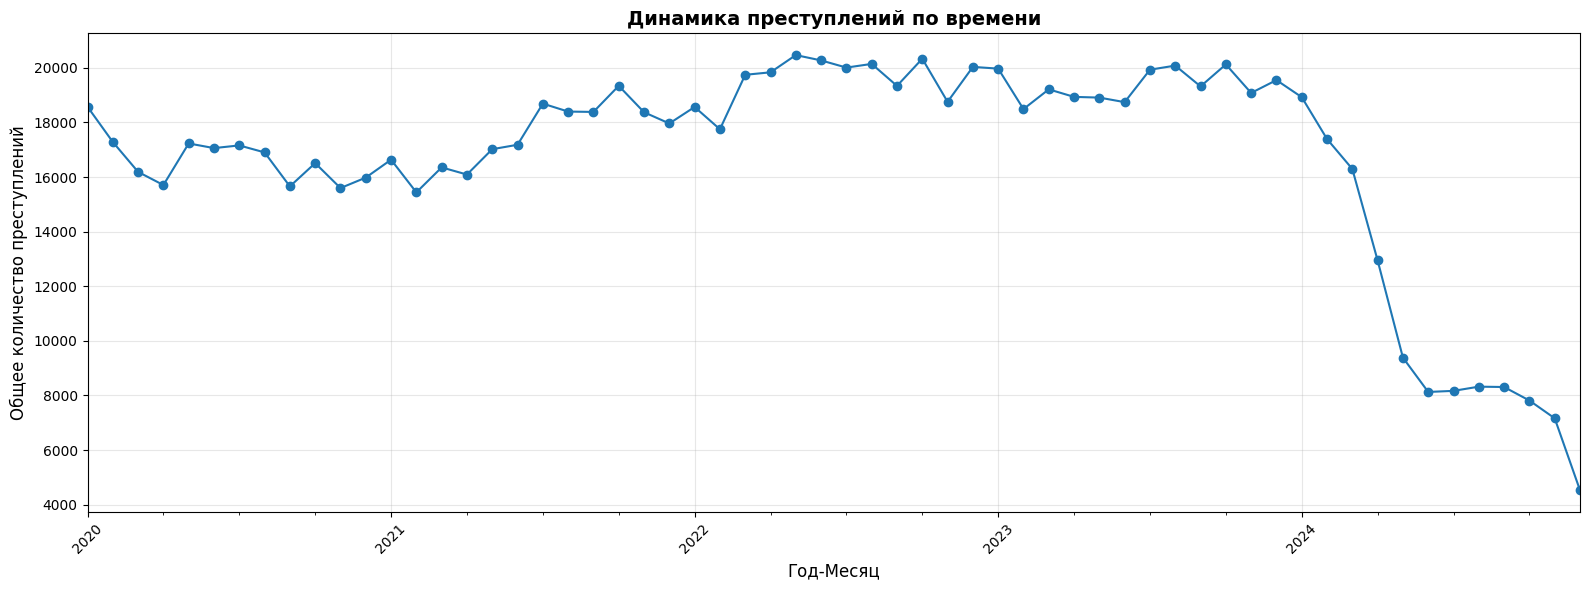

In [61]:
plt.figure(figsize=(16, 6))
crime_count_time = cube_time_area['Crime Count'].sum(axis=1)
crime_count_time.plot(kind='line', marker='o')
plt.title('Динамика преступлений по времени', fontsize=14, fontweight='bold')
plt.xlabel('Год-Месяц', fontsize=12)
plt.ylabel('Общее количество преступлений', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ЧАСТЬ 2: Аналитические вопросы

Создавайте кубы сами, чтобы ответить на поставленные вопросы. Используйте pandas pivot


## Вопрос 1: Сколько всего преступлений было зарегистрировано в каждом районе за 2021 год?

Добавьте визуализацию


In [62]:
q1 = pd.pivot_table(
    df_clean[df_clean['Year'] == 2021],
    values='Crime Count',
    index='Area Name',
    aggfunc='count'
).sort_values('Crime Count', ascending=False)

q1

,Crime Count
Area Name,
Central,13171
77th Street,13100
Pacific,12934
Hollywood,12108
Southwest,11419
N Hollywood,10932
Olympic,10834
Southeast,10434
Newton,9926


<Figure size 1400x700 with 0 Axes>

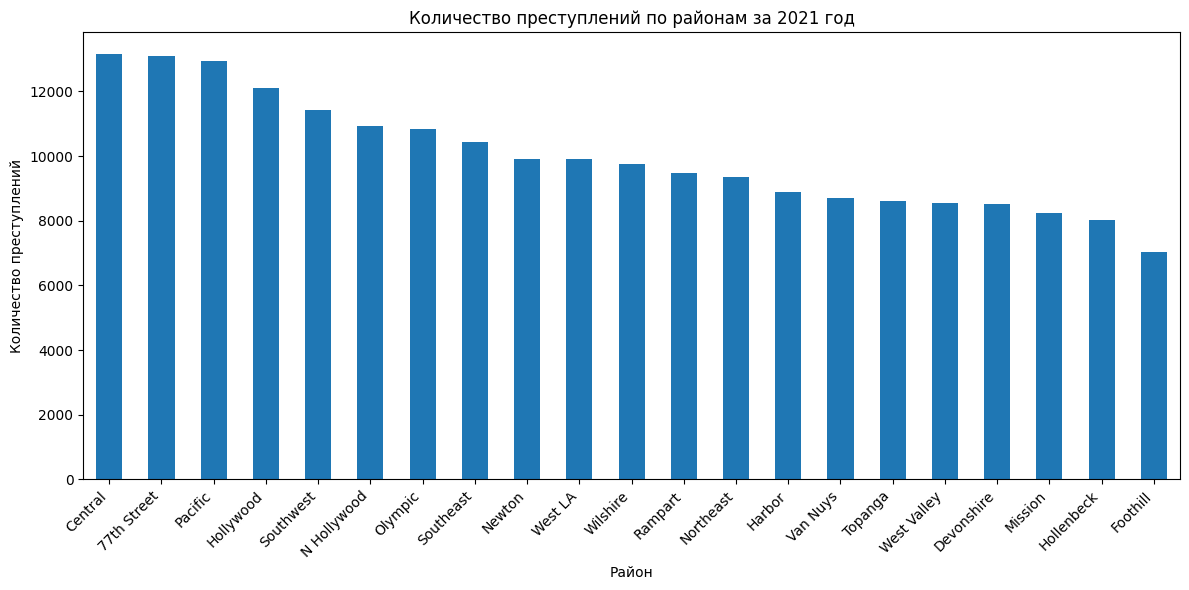

In [63]:
plt.figure(figsize=(14, 7))
q1.plot(kind='bar', legend=False)
plt.title('Количество преступлений по районам за 2021 год')
plt.xlabel('Район')
plt.ylabel('Количество преступлений')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## Вопрос 2: Что случилось на курсах по гольфу? Рассмотрите срезы по оружию, районам, видам преступлений


In [64]:
# Premise Code 144 соответствует Golf Course
golf = df_clean[df_clean['PremiseCode'] == '144'].copy()

golf_weapon = pd.pivot_table(golf, values='Crime Count', index='Weapon Description',
                             aggfunc='count').sort_values('Crime Count', ascending=False)
golf_area = pd.pivot_table(golf, values='Crime Count', index='Area Name',
                           aggfunc='count').sort_values('Crime Count', ascending=False)
golf_crime = pd.pivot_table(golf, values='Crime Count', index='CrimeCodeDescription',
                            aggfunc='count').sort_values('Crime Count', ascending=False)

print('Срез по оружию:')
display(golf_weapon.head(10))
print('Срез по районам:')
display(golf_area)
print('Срез по видам преступлений:')
display(golf_crime.head(10))


Срез по оружию:


,Crime Count
Weapon Description,
Unknown,153
"Strong-Arm (Hands, Fist, Feet Or Bodily Force)",10
Unknown Weapon/Other Weapon,6
Verbal Threat,3
Mace/Pepper Spray,2
Pipe/Metal Pipe,1
Brass Knuckles,1
Club/Bat,1


Срез по районам:


,Crime Count
Area Name,
West Valley,47
Pacific,27
Northeast,27
West LA,27
Foothill,19
Harbor,11
Devonshire,6
N Hollywood,5
Olympic,3


Срез по видам преступлений:


,Crime Count
CrimeCodeDescription,
Burglary From Vehicle,51
Burglary,22
Theft Plain - Petty ($950 & Under),21
"Theft-Grand ($950.01 & Over)Excpt,Guns,Fowl,Livestk,Prod",19
"Vandalism - Felony ($400 & Over, All Church Vandalisms)",15
Theft From Motor Vehicle - Grand ($950.01 And Over),13
Battery - Simple Assault,8
"Assault With Deadly Weapon, Aggravated Assault",6
Vandalism - Misdeameanor ($399 Or Under),5


## Вопрос 3: Какой тип преступления имеет самую сильную тяжесть? Как думаете, почему?


In [65]:
crime_severity = pd.pivot_table(
    df_clean,
    values='Severity',
    index='CrimeCodeDescription',
    aggfunc=['mean', 'count']
).sort_values(('mean', 'Severity'), ascending=False)

crime_severity.head(15)

,mean,count
,Severity,Severity
CrimeCodeDescription,,
"Theft, Coin Machine - Grand ($950.01 & Over)",7.200000,10
Firearms Emergency Protective Order (Firearms Epo),7.000000,5
Till Tap - Grand Theft ($950.01 & Over),6.875000,16
Failure To Disperse,6.500000,6
Petty Theft - Auto Repair,6.375000,8
Till Tap - Petty ($950 & Under),6.333333,24
Dishonest Employee Attempted Theft,6.250000,4
"Drugs, To A Minor",6.166667,12


## Вопрос 4: Какова средняя тяжесть преступлений, совершенных в месяц вашего рождения? Как думаете, почему?


In [66]:
birth_month = 11
q4 = pd.pivot_table(
    df_clean[df_clean['Month'] == birth_month],
    values='Severity',
    index='Month',
    aggfunc='mean'
)
print(f'Средняя тяжесть преступлений в месяце рождения ({birth_month}): {q4.iloc[0, 0]:.3f}')
q4

Средняя тяжесть преступлений в месяце рождения (11): 5.499


,Severity
Month,
11.0,5.49936


## Вопрос 5: Как меняется средний возраст жертвы по кварталам в Голливуде? Проиллюстрируйте графиком и прокомментируйте полученные результаты.


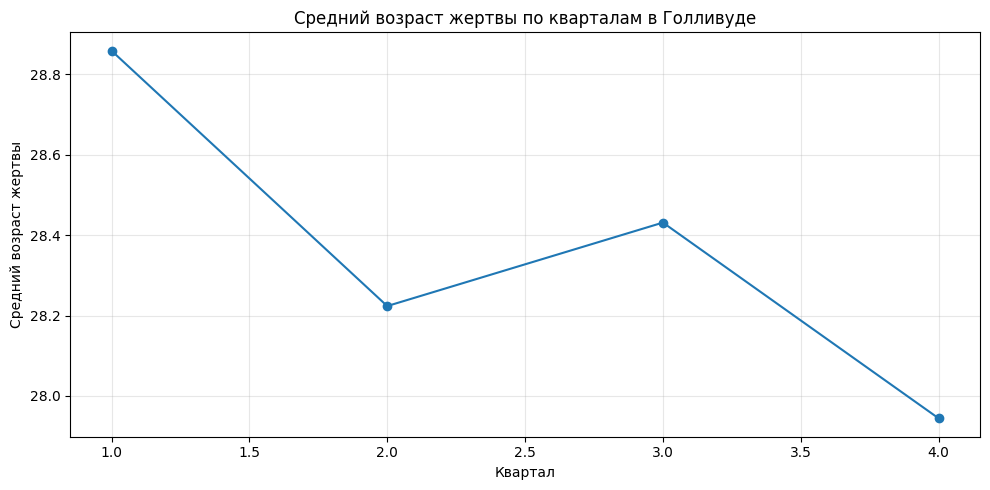

,Victim Age
Quarter,
1.0,28.858643
2.0,28.223497
3.0,28.431130
4.0,27.944205


In [67]:
hollywood = df_clean[df_clean['Area Name'] == 'Hollywood']
hollywood = hollywood.copy()
hollywood['Victim Age'] = pd.to_numeric(hollywood['Victim Age'], errors='coerce')
q5 = pd.pivot_table(
    hollywood,
    values='Victim Age',
    index='Quarter',
    aggfunc='mean'
).apply(pd.to_numeric, errors='coerce').dropna().sort_index()

q5.plot(kind='line', marker='o', legend=False, figsize=(10, 5))
plt.title('Средний возраст жертвы по кварталам в Голливуде')
plt.xlabel('Квартал')
plt.ylabel('Средний возраст жертвы')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
q5

## Вопрос 6: В каком месяце года произошло наибольшее количество преступлений с использованием холодного оружия?Какое оружие наиболее популярно? Как думаете, почему?

In [68]:
cold_weapon_mask = df_clean['Weapon Description'].str.contains(
    'Knife|Bowie|Blunt|Club|Bat|Scissors|Screwdriver|Machete|Sword|Razor|Bottle|Rock|Hammer',
    case=False, na=False
)
cold_weapons = df_clean[cold_weapon_mask]

q6_month = pd.pivot_table(cold_weapons, values='Crime Count', index='Month', aggfunc='count')
q6_weapon = pd.pivot_table(cold_weapons, values='Crime Count', index='Weapon Description', aggfunc='count').sort_values('Crime Count', ascending=False)

print('Количество преступлений с холодным оружием по месяцам:')
display(q6_month)
print('Самое популярное холодное оружие:')
display(q6_weapon.head(10))

Количество преступлений с холодным оружием по месяцам:


,Crime Count
Month,
1.0,2800
2.0,2679
3.0,2764
4.0,2708
5.0,2645
6.0,2665
7.0,2837
8.0,2805
9.0,2568


Самое популярное холодное оружие:


,Crime Count
Weapon Description,
Knife With Blade 6Inches Or Less,6837
Other Knife,5880
Rock/Thrown Object,2739
Bottle,2414
Folding Knife,2266
Club/Bat,2088
Kitchen Knife,1921
Knife With Blade Over 6 Inches In Length,1697
Blunt Instrument,1387


## Вопрос 7: В каких районах чаще всего происходили преступления связанные с похищением людей? А в каких локациях? Проиллюстрируйте графиками, сделайте выводы.


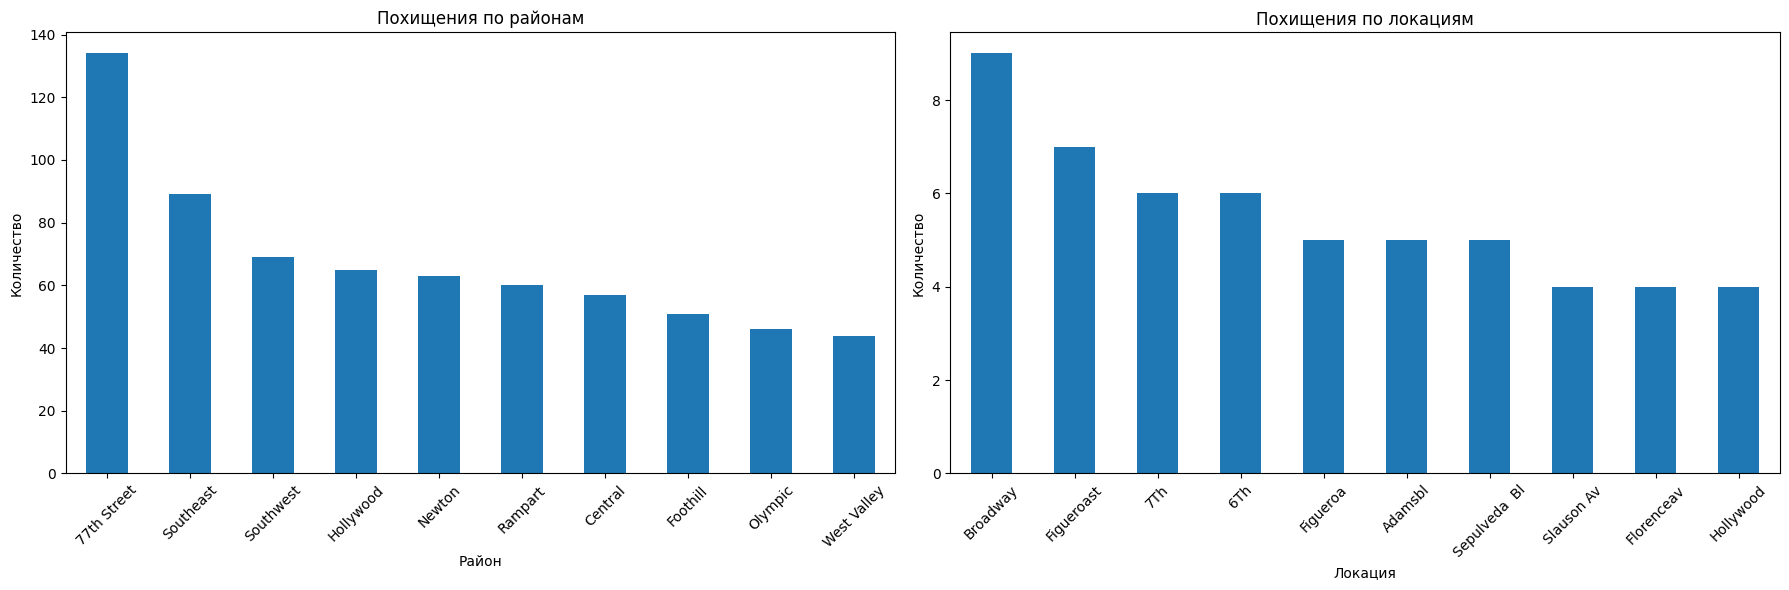

Топ районов:


,Crime Count
Area Name,
77th Street,134
Southeast,89
Southwest,69
Hollywood,65
Newton,63
Rampart,60
Central,57
Foothill,51
Olympic,46


Топ локаций:


,Crime Count
Location,
Broadway,9
Figueroast,7
7Th,6
6Th,6
Figueroa,5
Adamsbl,5
Sepulveda Bl,5
Slauson Av,4
Florenceav,4


In [69]:
kidnapping = df_clean[df_clean['CrimeCode'].isin(['910', '920'])]

q7_area = pd.pivot_table(kidnapping, values='Crime Count', index='Area Name',
                         aggfunc='count').sort_values('Crime Count', ascending=False)
q7_location = pd.pivot_table(kidnapping, values='Crime Count', index='Location',
                             aggfunc='count').sort_values('Crime Count', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
q7_area.head(10).plot(kind='bar', ax=axes[0], legend=False)
axes[0].set_title('Похищения по районам')
axes[0].set_xlabel('Район')
axes[0].set_ylabel('Количество')
axes[0].tick_params(axis='x', rotation=45)

q7_location.head(10).plot(kind='bar', ax=axes[1], legend=False)
axes[1].set_title('Похищения по локациям')
axes[1].set_xlabel('Локация')
axes[1].set_ylabel('Количество')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

print('Топ районов:')
display(q7_area.head(10))
print('Топ локаций:')
display(q7_location.head(10))

## Вопрос 8: Выведите количество преступлений по месяцам для самого опасного premise для женщин в 2022. Как думаете, почему самым опасным оказалось именно оно?


,Crime Count,Severity
Premise Description,,
Single Family Dwelling,24428,5.496807
"Multi-Unit Dwelling (Apartment, Duplex, Etc)",17423,5.498307
Street,12777,5.462159
Parking Lot,4685,5.404696
Sidewalk,3733,5.590946
"Vehicle, Passenger/Truck",2936,5.474114
Other Business,2026,5.501481
Garage/Carport,1463,5.425154
Driveway,1062,5.633710


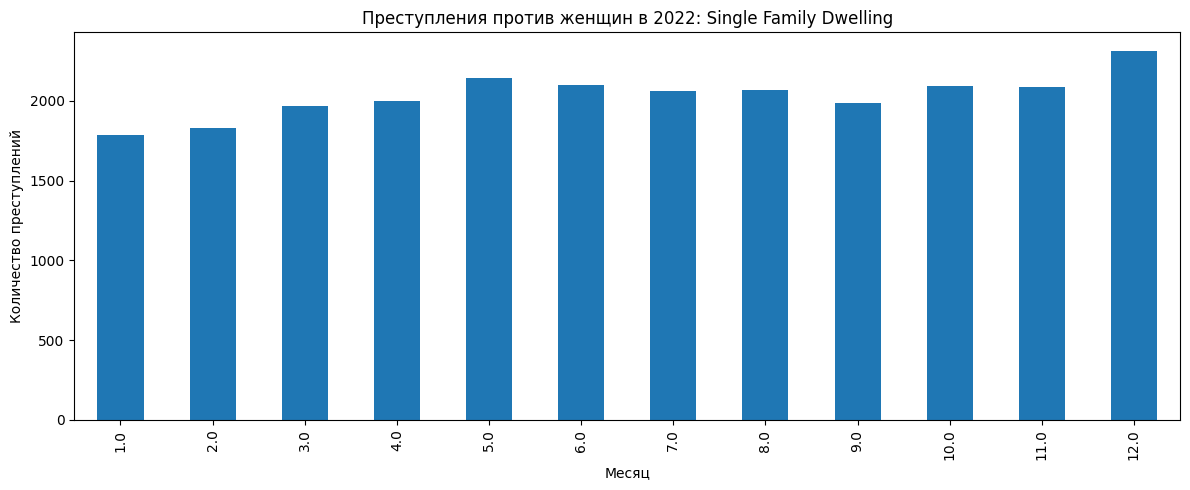

,Crime Count
Month,
1.0,1784
2.0,1827
3.0,1967
4.0,2000
5.0,2144
6.0,2098
7.0,2064
8.0,2070
9.0,1985


In [70]:
women_2022 = df_clean[(df_clean['Year'] == 2022) & (df_clean['Victim Gender'].isin(['F', 'Ж']))]

q8_premise = pd.pivot_table(
    women_2022,
    values=['Crime Count', 'Severity'],
    index='Premise Description',
    aggfunc={'Crime Count': 'count', 'Severity': 'mean'}
).sort_values('Crime Count', ascending=False)

display(q8_premise.head(10))

top_premise = q8_premise.index[0]
q8_month = pd.pivot_table(
    women_2022[women_2022['Premise Description'] == top_premise],
    values='Crime Count',
    index='Month',
    aggfunc='count'
).sort_index()

q8_month.plot(kind='bar', legend=False, figsize=(12, 5))
plt.title(f'Преступления против женщин в 2022: {top_premise}')
plt.xlabel('Месяц')
plt.ylabel('Количество преступлений')
plt.tight_layout()
plt.show()
q8_month